# Visualization & Baseline Model

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                              classification_report, confusion_matrix)

sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)

## Load the data

In [2]:
df = pd.read_csv("ai_jobs_salaries_clean.csv")
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Shape: 71,913 rows x 17 columns


## Data dictionary — what every column means

| Column | Meaning |
|---|---|
| `work_year` | Calendar year the salary record refers to (2020–2025) |
| `experience_level` | Seniority code: `EN`=Entry, `MI`=Mid, `SE`=Senior, `EX`=Executive |
| `employment_type` | `FT`=Full-time, `PT`=Part-time, `CT`=Contract, `FL`=Freelance |
| `job_title` | Free-text job title as originally posted (422 distinct values) |
| `salary` | Salary in the employee's local currency |
| `salary_currency` | ISO currency code for `salary` |
| `salary_in_usd` | Salary converted to USD — **this is our modeling target** |
| `employee_residence` | Country of residence of the employee (ISO alpha-2) |
| `remote_ratio` | % of work done remotely: 0 = on-site, 50 = hybrid, 100 = fully remote |
| `company_location` | Country where the hiring company is based (ISO alpha-2) |
| `company_size` | `S`=Small, `M`=Medium, `L`=Large |
| `experience_level_label`, `employment_type_label`, `work_mode` | Human-readable duplicates of the coded columns above |
| `salary_outlier_flag` | Boolean flag marking rows identified as salary outliers |
| `role_family` | A cleaned, 11-category grouping of `job_title` (e.g. Data Scientist, ML Engineer) |
| `isco_group_hint` | A rough mapping from `role_family` to a broad ILO/ISCO-08 occupational category — see the dedicated section below |

### `isco_group_hint`

This column connects some of our job roles to occupational categories from the ILO's Generative AI and Jobs paper by Gmyrek et al. (2025). The paper looks at how much different jobs may be affected by generative AI.

The researchers gave occupations an exposure score from 0 to 1. A higher score means more of the job's tasks could potentially be done or helped by generative AI. They also grouped jobs into different exposure levels based on their scores and how consistently their tasks are affected.

Only 5 of our 11 role_family groups have a matching `isco_group_hint`, covering about 44% of the records. The other role groups were not matched to an ISCO-08 category in the dataset.

In [3]:
iso_counts = df["isco_group_hint"].value_counts(dropna=False)
print(iso_counts)
print()
print("Which role_family maps to which isco_group_hint:")
print(df.dropna(subset=["isco_group_hint"]).groupby("isco_group_hint")["role_family"].value_counts())

isco_group_hint
NaN                                                           40540
Software and applications developers                          12475
Business services and administration managers                  8335
Mathematicians, actuaries and statisticians                    7216
Physical and earth science professionals                       2852
Information and communications technology service managers      495
Name: count, dtype: int64

Which role_family maps to which isco_group_hint:
isco_group_hint                                             role_family       
Business services and administration managers               Data Analyst          8335
Information and communications technology service managers  Analytics Manager      495
Mathematicians, actuaries and statisticians                 Data Scientist        7216
Physical and earth science professionals                    Research Scientist    2852
Software and applications developers                        Data Engineer

Each populated `isco_group_hint` value corresponds almost 1-to-1 with a single `role_family` (e.g. every `Data Scientist` row is tagged `Mathematicians, actuaries and statisticians`). So `isco_group_hint` doesn't add new information beyond `role_family` for rows where it's populated, its real value is as a bridge to the ILO paper's exposure scores, not as a standalone predictor.

## Missing values

In [4]:
missing = pd.DataFrame({
    "n_missing": df.isnull().sum(),
    "pct_missing": (df.isnull().sum() / len(df) * 100).round(2)
}).sort_values("n_missing", ascending=False)
missing[missing["n_missing"] > 0]

`isco_group_hint` is the only column with missing values (~56% missing), consistent with it only covering 5 of the 11 role families. Every other column is fully populated, so no imputation is needed elsewhere.

## Variable balance 

In [5]:
cat_cols = ["experience_level", "employment_type", "company_size", "remote_ratio",
            "work_mode", "role_family", "work_year", "salary_outlier_flag"]

for c in cat_cols:
    print(f"--- {c} ---")
    print((df[c].value_counts(normalize=True) * 100).round(2).to_string())
    print()

--- experience_level ---
experience_level
SE    52.43
MI    32.53
EN    11.09
EX     3.95

--- employment_type ---
employment_type
FT    98.96
CT     0.53
PT     0.49
FL     0.02

--- company_size ---
company_size
M    97.49
L     2.21
S     0.30

--- remote_ratio ---
remote_ratio
0      75.20
100    24.34
50      0.45

--- work_mode ---
work_mode
On-site    75.20
Remote     24.34
Hybrid      0.45

--- role_family ---
role_family
Other / Unclassified    56.37
Data Analyst            11.59
Data Engineer           10.08
Data Scientist          10.03
ML Engineer              5.06
Research Scientist       3.97
AI Engineer              1.68
Analytics Manager        0.69
AI Architect             0.30
Computer Vision          0.19
NLP                      0.03

--- work_year ---
work_year
2025    53.23
2024    38.50
2023     6.31
2022     1.55
2021     0.30
2020     0.10

--- salary_outlier_flag ---
salary_outlier_flag
False    97.56
True      2.44



- `experience_level` is imbalanced — Senior (52%) dominates, Executive is rare (4%)
- `employment_type` is heavily imbalanced — 99% Full-time
- `company_size` is heavily imbalanced — 97% Medium
- `remote_ratio` is imbalanced — On-site (75%) and Remote (24%) dominate; Hybrid is under 1%
- `role_family` is imbalanced — 56% is "Other / Unclassified"
- `work_year` is skewed toward recent years — 2024–2025 alone make up ~92% of rows
- `salary_outlier_flag` is imbalanced by design — only ~2.4% are flagged

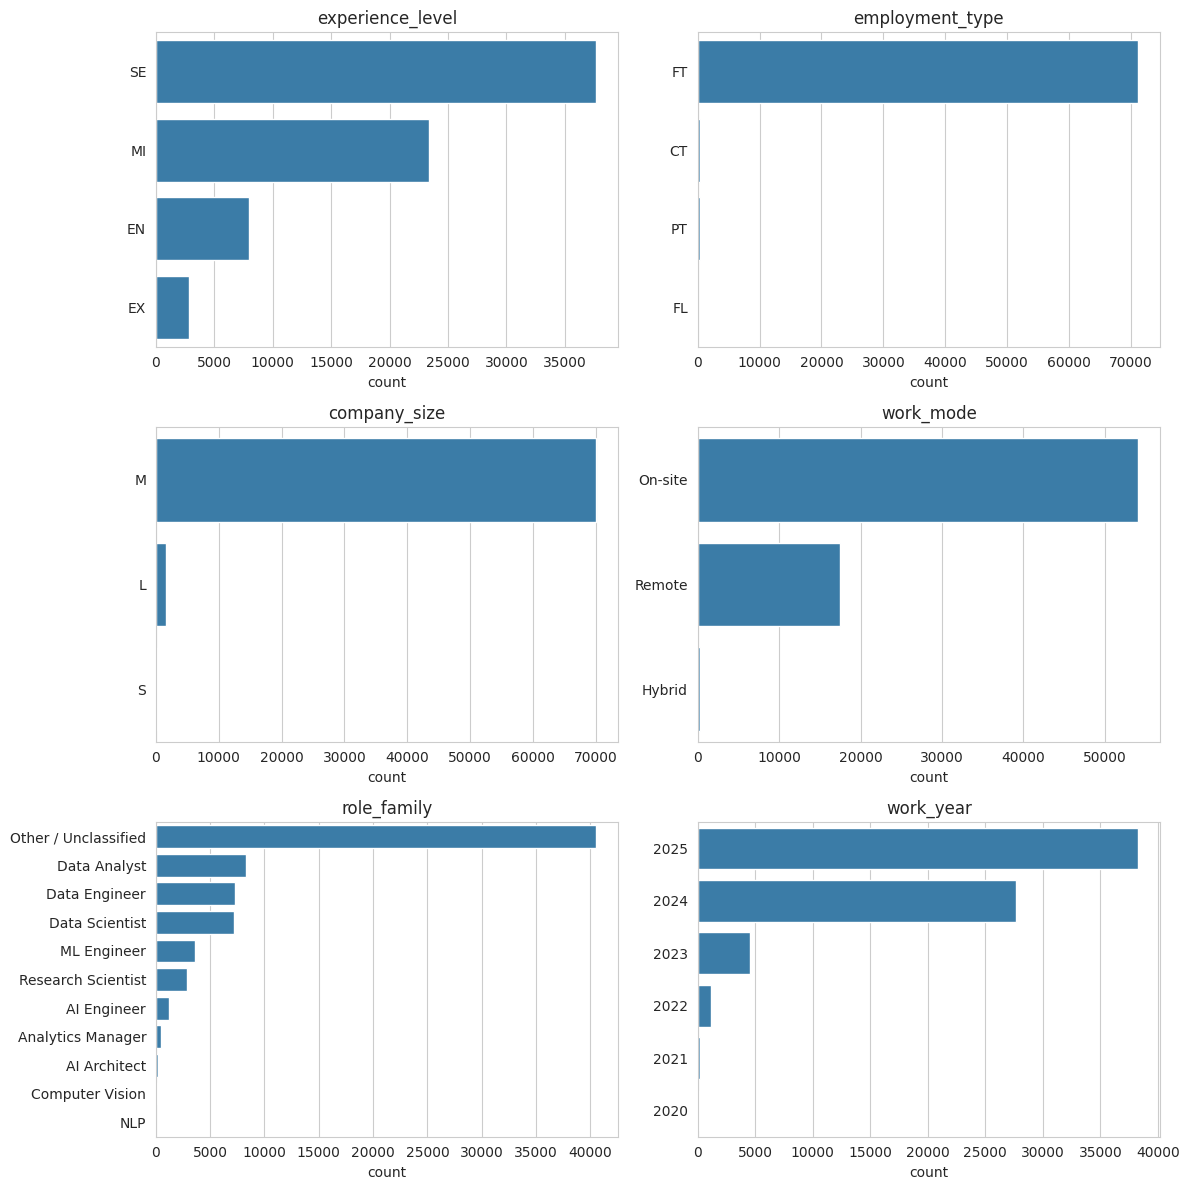

In [6]:
fig, axes = plt.subplots(3, 2, figsize=(12, 12))
axes = axes.ravel()
plot_cols = ["experience_level", "employment_type", "company_size", "work_mode", "role_family", "work_year"]
for ax, c in zip(axes, plot_cols):
    order = df[c].value_counts().index
    sns.countplot(data=df, y=c, order=order, ax=ax, color="#2980b9")
    ax.set_title(c)
    ax.set_xlabel("count")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

Most bars are dominated by one or two categories, with long tails of rare ones (Contract/Freelance/Part-time, Small/Large company size, Executive level).

## Salary distribution

count     71913.000000
mean     151161.252625
std       77329.594122
min       15000.000000
25%       96000.000000
50%      138750.000000
75%      190315.000000
max      800000.000000
Name: salary_in_usd, dtype: float64
Skewness: 1.48


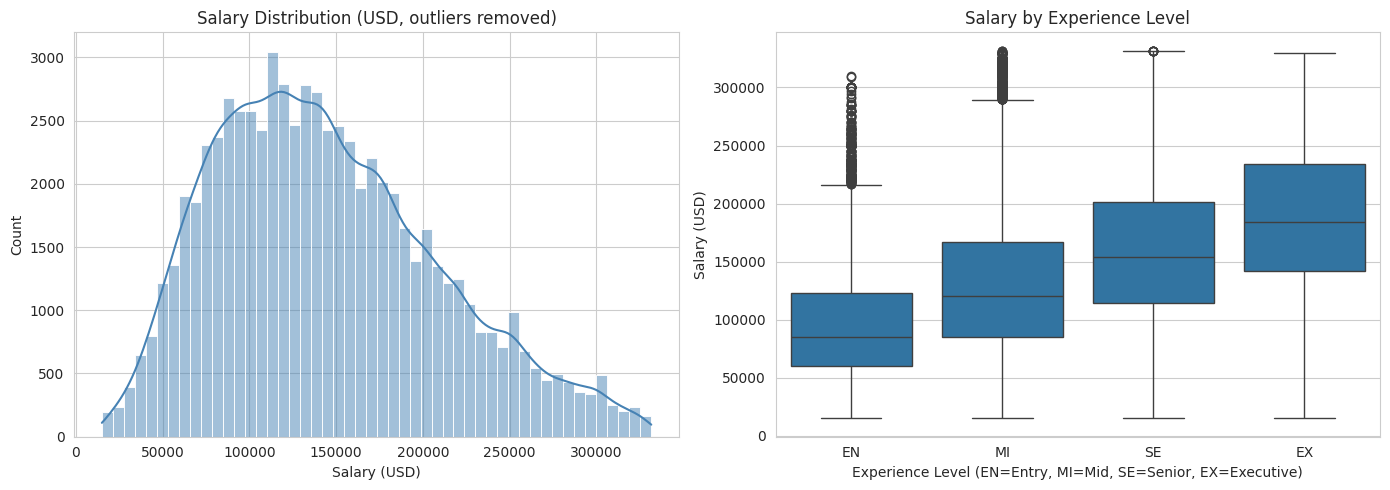

In [7]:
# I used an outlier-free view (df_clean) only for cleaner visualization.
# salary_outlier_flag is NOT used as a modeling feature later (see leakage section) —
# here it's purely a plotting convenience so extreme values don't compress the histogram.
df_clean = df[df["salary_outlier_flag"] == False].copy()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df_clean["salary_in_usd"], bins=50, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title("Salary Distribution (USD, outliers removed)")
axes[0].set_xlabel("Salary (USD)")

sns.boxplot(data=df_clean, x="experience_level", y="salary_in_usd", ax=axes[1],
            order=["EN", "MI", "SE", "EX"])
axes[1].set_title("Salary by Experience Level")
axes[1].set_xlabel("Experience Level (EN=Entry, MI=Mid, SE=Senior, EX=Executive)")
axes[1].set_ylabel("Salary (USD)")

plt.tight_layout()
plt.show()

print(df["salary_in_usd"].describe())
print("Skewness:", df["salary_in_usd"].skew().round(3))

- The salary distribution is right-skewed with a long tail of high earners, typical of salary data, and the reason we log-transform in some later analyses.
- Salary rises clearly and monotonically with experience level: Entry-level salaries cluster lowest, Executive-level highest, with each step up in seniority also widening the spread (more variance in how senior roles are paid).

## Average salary by role family

                          mean    median  count
role_family                                    
AI Architect          192781.0  185000.0    199
Research Scientist    177687.0  173366.0   2642
ML Engineer           176789.0  171080.0   3460
Analytics Manager     168747.0  161400.0    459
Computer Vision       161895.0  170000.0    134
AI Engineer           154529.0  147500.0   1165
Data Scientist        147433.0  140109.0   7102
Other / Unclassified  146617.0  138500.0  39498
Data Engineer         141937.0  135000.0   7168
NLP                   134649.0  150000.0     19
Data Analyst          107661.0   99200.0   8313


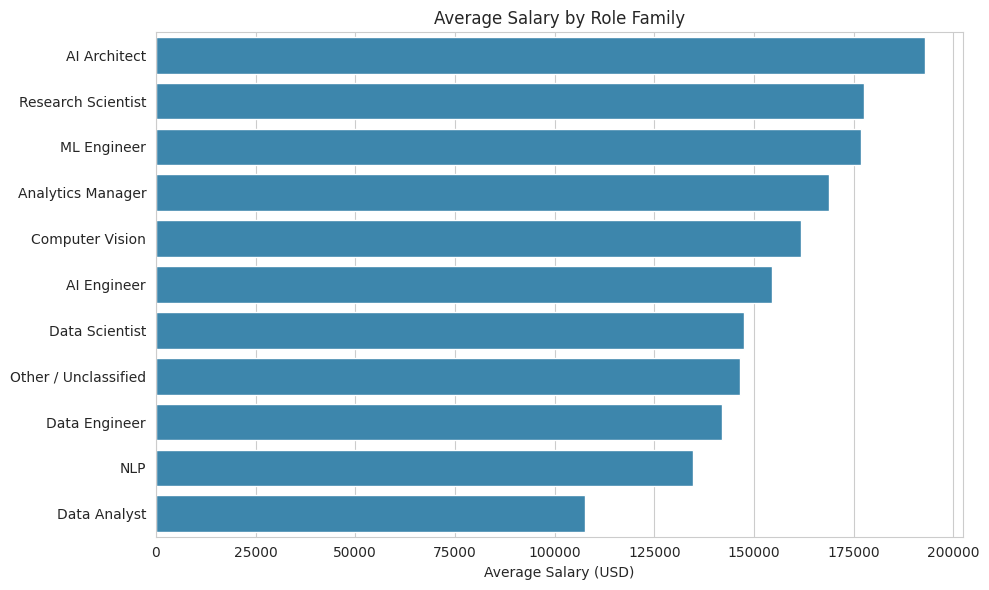

In [8]:
role_salary = df_clean.groupby("role_family")["salary_in_usd"].agg(["mean", "median", "count"]).sort_values("mean", ascending=False)
print(role_salary.round(0))

plt.figure(figsize=(10, 6))
sns.barplot(data=df_clean, y="role_family", x="salary_in_usd",
            order=role_salary.index, estimator="mean", errorbar=None, color="#2b8cbe")
plt.title("Average Salary by Role Family")
plt.xlabel("Average Salary (USD)")
plt.ylabel("")
plt.tight_layout()
plt.show()

Management and architect-track roles (AI Architect, Analytics Manager) sit at the top, core ML/research roles (Research Scientist, ML Engineer, Data Scientist) sit in the upper-middle, and Data Analyst sits lowest among the classified roles — consistent with typical seniority and specialization patterns in the field. "Other / Unclassified" (56% of the data) sits close to the middle, which is expected since it's a mixed bag of many different job titles rather than a single role type.

## Correlation between numeric variables

               work_year  salary_in_usd  remote_ratio
work_year          1.000          0.018        -0.100
salary_in_usd      0.018          1.000         0.002
remote_ratio      -0.100          0.002         1.000


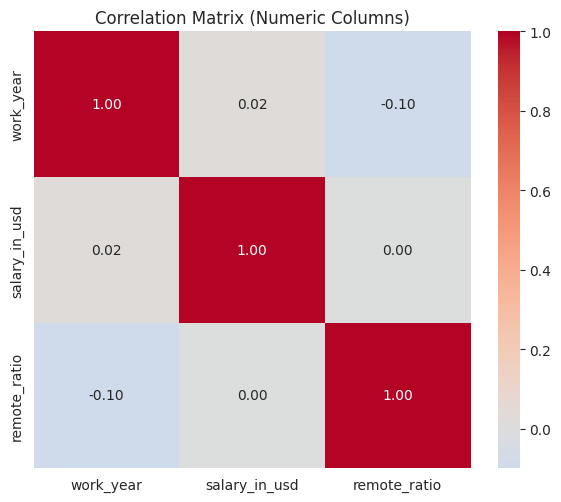

In [9]:
numeric_cols = ["work_year", "salary_in_usd", "remote_ratio"]
corr_matrix = df_clean[numeric_cols].corr()
print(corr_matrix.round(3))

plt.figure(figsize=(6, 5))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", center=0, fmt=".2f", square=True)
plt.title("Correlation Matrix (Numeric Columns)")
plt.tight_layout()
plt.show()

None of the three numeric columns are strongly correlated with each other or with salary in a linear sense (all correlations are weak). That doesn't mean `work_year` or `remote_ratio` are useless, their relationship with salary is more about differences between categories (e.g. On-site vs Remote, 2020 vs 2025) than a straight linear trend, which the boxplots below capture better than a correlation coefficient can.

## Salary by work arrangement

                           mean    median  count
work_arrangement                                
Hybrid             78841.086420   68276.0    324
On-site           144843.003576  136000.0  52570
Remote            145486.145207  140000.0  17265


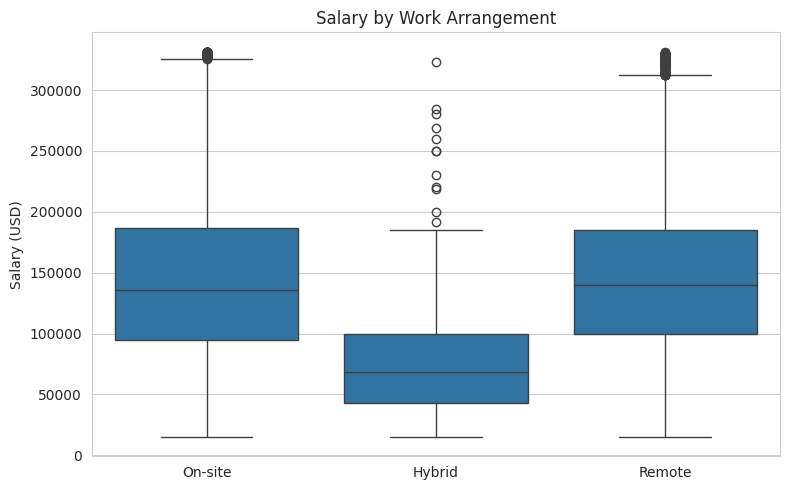

In [10]:
remote_labels = {0: "On-site", 50: "Hybrid", 100: "Remote"}
df_clean["work_arrangement"] = df_clean["remote_ratio"].map(remote_labels)

print(df_clean.groupby("work_arrangement")["salary_in_usd"].agg(["mean", "median", "count"]))

plt.figure(figsize=(8, 5))
sns.boxplot(data=df_clean, x="work_arrangement", y="salary_in_usd", order=["On-site", "Hybrid", "Remote"])
plt.title("Salary by Work Arrangement")
plt.xlabel("")
plt.ylabel("Salary (USD)")
plt.tight_layout()
plt.show()

In [11]:
hybrid_data = df_clean[df_clean["work_arrangement"] == "Hybrid"]
print("=== Top role families in Hybrid ===")
print(hybrid_data["role_family"].value_counts().head(5))
print("\n=== Top countries in Hybrid ===")
print(hybrid_data["company_location"].value_counts().head(5))
print("\n=== Experience levels in Hybrid ===")
print(hybrid_data["experience_level"].value_counts())

=== Top role families in Hybrid ===
role_family
Data Scientist          99
Other / Unclassified    69
Data Analyst            45
Data Engineer           42
ML Engineer             30
Name: count, dtype: int64

=== Top countries in Hybrid ===
company_location
US    54
GB    34
DE    30
FR    29
IN    24
Name: count, dtype: int64

=== Experience levels in Hybrid ===
experience_level
MI    121
EN    105
SE     87
EX     11
Name: count, dtype: int64


Hybrid pays noticeably less on average (~\$79K) than On-site or Remote (~\$144–145K each), but this is almost certainly because Hybrid is a tiny group (only ~324 rows), skewed toward lower-paying roles and Entry/Mid-level experience, with very few Executives. In other words, Hybrid isn't underpaid because it's hybrid, the group happens to be made up of the kinds of roles and seniority levels that pay less anyway.

## Salary trends over time, by role family

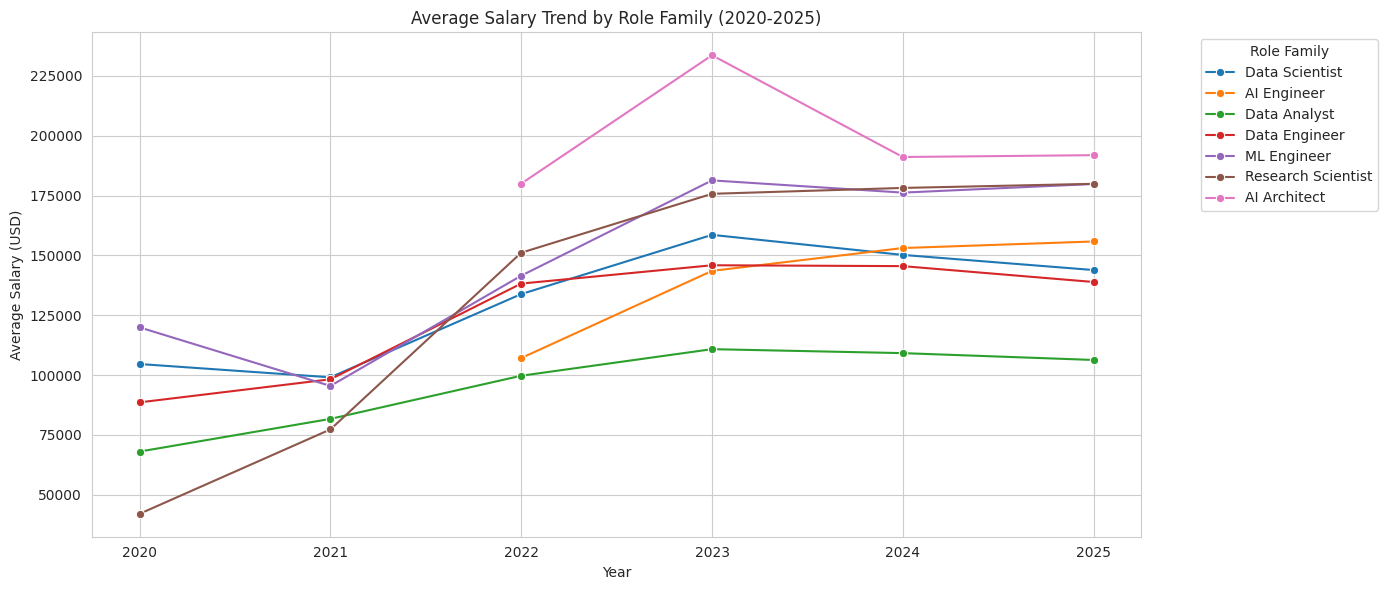

In [12]:
key_roles = ["AI Architect", "Research Scientist", "ML Engineer", "AI Engineer",
             "Data Scientist", "Data Analyst", "Data Engineer"]
trend_data = df_clean[df_clean["role_family"].isin(key_roles)]

plt.figure(figsize=(14, 6))
sns.lineplot(data=trend_data, x="work_year", y="salary_in_usd", hue="role_family",
             estimator="mean", errorbar=None, marker="o")
plt.title("Average Salary Trend by Role Family (2020-2025)")
plt.xlabel("Year")
plt.ylabel("Average Salary (USD)")
plt.legend(title="Role Family", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

Note on scope: I deliberately restrict this trend view to the 7 explicitly classified role families and exclude "Other / Unclassified." Since that catch-all bucket mixes ~330 different job titles, a year-over-year "trend" for it would really just reflect which titles happened to be posted that year.

Most classified roles show a generally rising average salary from 2020 to 2025, with more visible year-to-year swings in the earliest years, expected, since 2020–2022 have far fewer records and small samples are noisier.

## Work arrangement mix over time

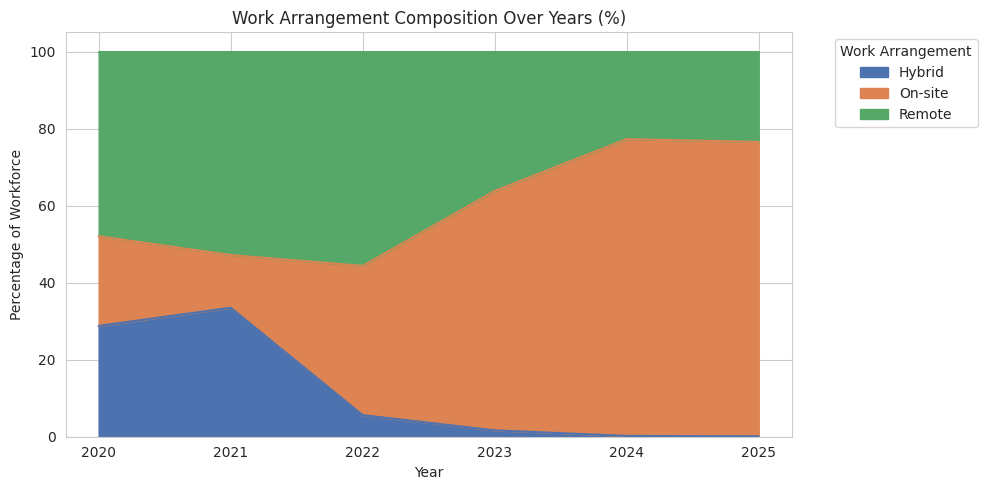

In [13]:
plt.figure(figsize=(10, 5))
work_mode_trend = pd.crosstab(df_clean["work_year"], df_clean["work_arrangement"], normalize="index") * 100
work_mode_trend.plot(kind="area", stacked=True, ax=plt.gca(), color=["#4C72B0", "#DD8452", "#55A868"])
plt.title("Work Arrangement Composition Over Years (%)")
plt.xlabel("Year")
plt.ylabel("Percentage of Workforce")
plt.legend(title="Work Arrangement", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

The share of fully On-site roles grows sharply in the later years while Remote's share shrinks,a visible pullback from the remote-heavy hiring seen right after 2020–2021. Hybrid stays a thin sliver throughout, never becoming a major category.

## `isco_group_hint` and AI exposure scores

Here I use the exposure scores from the ILO paper, found on pages 48–52. The scores are averaged across the relevant 4-digit ISCO-08 occupations for each of our five isco_group_hint categories.

Recall: higher score = greater estimated potential for generative-AI task automation within that occupation.

In [14]:
# Approximate exposure scores (0-1 scale), averaged from Gmyrek et al. (2025), Table A1,
# over the 4-digit ISCO-08 occupations underlying each isco_group_hint category.
gmyrek_scores = {
    'Information and communications technology service managers': 0.440,
    'Mathematicians, actuaries and statisticians': 0.561,
    'Software and applications developers': 0.527,
    'Business services and administration managers': 0.419,
    'Physical and earth science professionals': 0.411,
}

df["gmyrek_exposure_score"] = df["isco_group_hint"].map(gmyrek_scores)
print(df["gmyrek_exposure_score"].value_counts(dropna=False))
print(f"\nMatched: {df['gmyrek_exposure_score'].notna().sum()} / {df['isco_group_hint'].notna().sum()} mapped rows")

gmyrek_exposure_score
NaN      40540
0.527    12475
0.419     8335
0.561     7216
0.411     2852
0.440      495
Name: count, dtype: int64

Matched: 31373 / 31373 mapped rows


                                                    mean_salary  \
isco_group_hint                                                   
Physical and earth science professionals               195300.2   
Business services and administration managers          108602.0   
Information and communications technology servi...     185237.6   
Software and applications developers                   160638.7   
Mathematicians, actuaries and statisticians            151556.6   

                                                    exposure_score      n  
isco_group_hint                                                            
Physical and earth science professionals                       0.4   2852  
Business services and administration managers                  0.4   8335  
Information and communications technology servi...             0.4    495  
Software and applications developers                           0.5  12475  
Mathematicians, actuaries and statisticians                    0.6   7216 

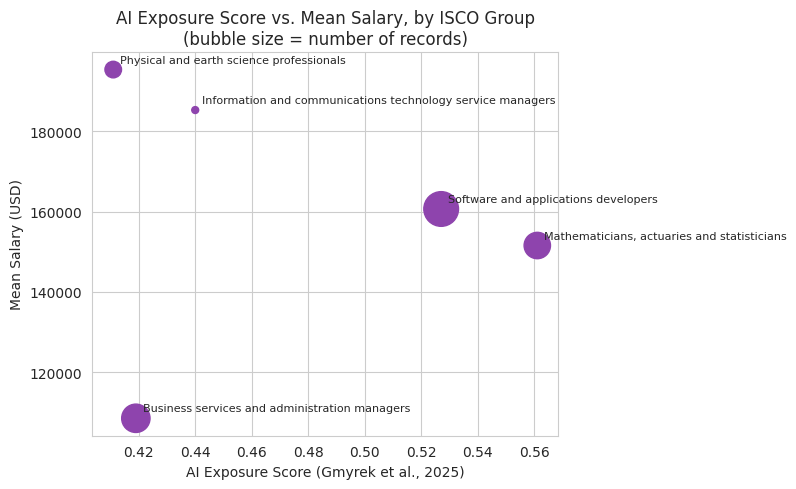

In [15]:
exposure_salary = (df.dropna(subset=["gmyrek_exposure_score"])
                      .groupby("isco_group_hint")
                      .agg(mean_salary=("salary_in_usd", "mean"),
                           exposure_score=("gmyrek_exposure_score", "first"),
                           n=("salary_in_usd", "count"))
                      .sort_values("exposure_score"))
print(exposure_salary.round(1))

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(exposure_salary["exposure_score"], exposure_salary["mean_salary"], s=exposure_salary["n"]/20, color="#8e44ad")
for label, row in exposure_salary.iterrows():
    ax.annotate(label, (row["exposure_score"], row["mean_salary"]), fontsize=8, xytext=(5,5), textcoords="offset points")
ax.set_xlabel("AI Exposure Score (Gmyrek et al., 2025)")
ax.set_ylabel("Mean Salary (USD)")
ax.set_title("AI Exposure Score vs. Mean Salary, by ISCO Group\n(bubble size = number of records)")
plt.tight_layout()
plt.show()

Across the 5 groups, there is no clear relationship between AI exposure and average salary. The results are only exploratory due to the small number of groups, but they show how the dataset can be combined with external research like the ILO paper for further analysis.

## Data leakage audit

Before modeling, we check whether any column is a duplicate or downstream derivative of another column

In [16]:
print("salary == salary_in_usd?", df["salary"].equals(df["salary_in_usd"]))
usd_rows = df[df["salary_currency"] == "USD"]
print("For USD-currency rows, salary == salary_in_usd for",
      round((usd_rows["salary"] == usd_rows["salary_in_usd"]).mean() * 100, 1), "% of rows")
print()
print(df.groupby("salary_outlier_flag")["salary_in_usd"].describe())

salary == salary_in_usd? False
For USD-currency rows, salary == salary_in_usd for 100.0 % of rows

                       count           mean           std       min       25%  \
salary_outlier_flag                                                             
False                70159.0  144696.468122  64832.364871   15000.0   95000.0   
True                  1754.0  409748.946978  92242.103181  332000.0  350000.0   

                          50%       75%       max  
salary_outlier_flag                                
False                136700.0  185800.0  331640.0  
True                 376000.0  429415.0  800000.0  


Findings:
 - salary and salary_currency leak the target because they can directly reproduce salary_in_usd → drop both.
 - salary_outlier_flag appears to be calculated from salary_in_usd → drop it.
 - experience_level_label, employment_type_label, and work_mode duplicate existing variables → drop them.
 - job_title has 422 categories and is largely captured by role_family → drop job_title, keep role_family.
 - isco_group_hint is ~56% missing and closely overlaps with role_family → drop it from the model.

### Columns going into the model
Target: `salary_in_usd` (binned into tiers)
Features: `work_year`, `experience_level`, `employment_type`, `employee_residence`, `remote_ratio`, `company_location`, `company_size`, `role_family`


In [17]:
drop_cols = ["salary", "salary_currency", "salary_outlier_flag",
             "experience_level_label", "employment_type_label", "work_mode",
             "job_title", "isco_group_hint", "gmyrek_exposure_score"]
model_df = df.drop(columns=drop_cols)
print("Modeling columns:", list(model_df.columns))

Modeling columns: ['work_year', 'experience_level', 'employment_type', 'salary_in_usd', 'employee_residence', 'remote_ratio', 'company_location', 'company_size', 'role_family']


## 13. Baseline model — predicting a salary tier

Since salary_in_usd is a continuous value, accuracy, precision, recall, and F1 are not directly applicable because they are classification metrics. To use these metrics, I turn salary prediction into a classification problem by dividing salaries into four quartile-based tiers: Low, Lower-Mid, Upper-Mid, and High. 
This keeps the groups roughly balanced at 25% each. Because each row is an independent job record, we use a random train/test split. 
To prevent test-set information from affecting the results, we calculate the quartile boundaries using only the training data and then apply those same boundaries to the test data.

In [18]:
X = model_df.drop(columns=["salary_in_usd"])
y_raw = model_df["salary_in_usd"]

X_train, X_test, y_train_raw, y_test_raw = train_test_split(X, y_raw, test_size=0.2, random_state=42)

# Define quartile tiers using TRAIN data only, then apply the same boundaries to test
y_train_binned, bin_edges = pd.qcut(y_train_raw, q=4, labels=["Low", "Lower-Mid", "Upper-Mid", "High"], retbins=True)

# Apply train-derived edges to the test set; clip so out-of-range test values fall into the end bins
bin_edges_applied = bin_edges.copy()
bin_edges_applied[0] = -np.inf
bin_edges_applied[-1] = np.inf
y_test_binned = pd.cut(y_test_raw, bins=bin_edges_applied, labels=["Low", "Lower-Mid", "Upper-Mid", "High"])

y_train = y_train_binned
y_test = y_test_binned

print("Quartile boundaries (from training data, USD):", bin_edges.round(0).tolist())
print()
print("Train class balance:")
print(y_train.value_counts(normalize=True).round(3))
print()
print("Test class balance:")
print(y_test.value_counts(normalize=True).round(3))

Quartile boundaries (from training data, USD): [15000.0, 96000.0, 138750.0, 190200.0, 800000.0]

Train class balance:
salary_in_usd
Low          0.25
High         0.25
Upper-Mid    0.25
Lower-Mid    0.25
Name: proportion, dtype: float64

Test class balance:
salary_in_usd
High         0.251
Lower-Mid    0.251
Upper-Mid    0.249
Low          0.249
Name: proportion, dtype: float64


The quartile tiers are, by construction, almost exactly balanced in the training set (~25% each), and applying those same boundaries to the test set keeps it close to balanced too, confirming a plain random split works fine here without needing extra stratification.

In [19]:
categorical_features = ["experience_level", "employment_type", "employee_residence",
                         "company_location", "company_size", "role_family"]
numeric_features = ["work_year", "remote_ratio"]
# One-hot encoding produces ~200 sparse columns; scaling the two numeric columns
# (work_year, remote_ratio) puts everything on a comparable scale so the solver converges cleanly.

preprocess = ColumnTransformer(transformers=[
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ("num", StandardScaler(), numeric_features),
])

def evaluate(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average="macro", zero_division=0)
    rec = recall_score(y_true, y_pred, average="macro", zero_division=0)
    f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)
    print(f"{name:20s}  Accuracy: {acc:.3f}   Precision (macro): {prec:.3f}   Recall (macro): {rec:.3f}   F1 (macro): {f1:.3f}")
    return {"model": name, "Accuracy": acc, "Precision": prec, "Recall": rec, "F1": f1}

results = []

In [20]:
# Baseline 1: predict the most frequent class every time
dummy = DummyClassifier(strategy="most_frequent", random_state=42)
dummy.fit(X_train, y_train)
pred_dummy = dummy.predict(X_test)
results.append(evaluate("Dummy (most frequent)", y_test, pred_dummy))

Dummy (most frequent)  Accuracy: 0.249   Precision (macro): 0.062   Recall (macro): 0.250   F1 (macro): 0.100


In [21]:
# Baseline 2: Logistic Regression on one-hot encoded features
clf_pipeline = Pipeline(steps=[
    ("preprocess", preprocess),
    ("model", LogisticRegression(max_iter=2000))
])
clf_pipeline.fit(X_train, y_train)
pred_clf = clf_pipeline.predict(X_test)
results.append(evaluate("Logistic Regression", y_test, pred_clf))

Logistic Regression   Accuracy: 0.418   Precision (macro): 0.419   Recall (macro): 0.417   F1 (macro): 0.392


In [22]:
results_df = pd.DataFrame(results).set_index("model")
results_df.round(3)

In [23]:
print(classification_report(y_test, pred_clf, target_names=["Low", "Lower-Mid", "Upper-Mid", "High"]))

              precision    recall  f1-score   support

         Low       0.40      0.65      0.49      3617
   Lower-Mid       0.62      0.54      0.57      3575
   Upper-Mid       0.32      0.38      0.35      3613
        High       0.34      0.10      0.15      3578

    accuracy                           0.42     14383
   macro avg       0.42      0.42      0.39     14383
weighted avg       0.42      0.42      0.39     14383



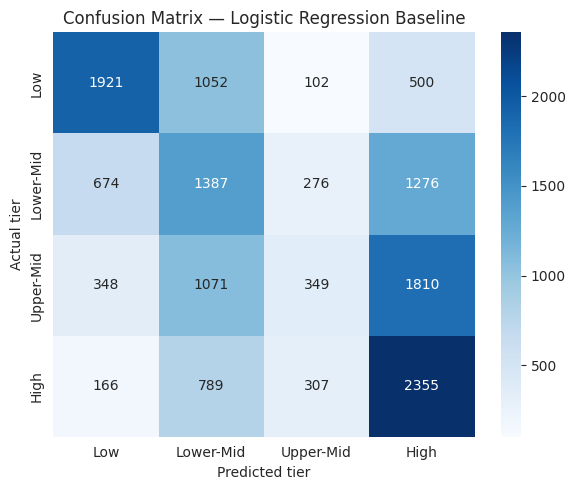

In [24]:
cm = confusion_matrix(y_test, pred_clf, labels=["Low", "Lower-Mid", "Upper-Mid", "High"])
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Low", "Lower-Mid", "Upper-Mid", "High"],
            yticklabels=["Low", "Lower-Mid", "Upper-Mid", "High"])
plt.xlabel("Predicted tier")
plt.ylabel("Actual tier")
plt.title("Confusion Matrix — Logistic Regression Baseline")
plt.tight_layout()
plt.show()

- Logistic Regression performs better than the Dummy baseline on every metric, showing that the features provide useful information for predicting salary tier.
- Most errors are between neighboring tiers rather than extreme tiers, which makes sense because salary is continuous and the tier cutoffs are somewhat arbitrary.
- `experience_level` and `role_family` likely contribute the most to the model, based on their strong relationship with salary seen earlier.

## Summary & next steps

What I covered:
- Documented every column, including `isco_group_hint` and its connection to the ILO's GenAI research.
- Found missing values in `isco_group_hint` and explained why they were not imputed.
- Checked categorical variables for imbalance and identified several heavily imbalanced features.
- Visualized salary by experience, role, work arrangement, and time, with a takeaway for each.
- Explored an exploratory join with the ILO's AI exposure scores.
- Removed data leakage from `salary`, `salary_currency`, and `salary_outlier_flag`, along with duplicate labels and high-cardinality job_title.
- Built a baseline model to predict four salary tiers using a leak-safe train/test split and reported accuracy, precision, recall, and F1.

Possible next steps:
- Try more salary tiers, such as deciles, or use salary as a continuous regression target.
- Add features like the ILO exposure score or frequency-encoded `employee_residence`.
- Test stronger models, such as Random Forest or Gradient Boosting.
- Check whether prediction errors are concentrated in certain roles or countries.